Part 4D: Monthly and cumulative returns, NVDL vs NVDA

**Question.** For each calendar month (February to August 2024) and for the whole window, compute the total return of NVDL and NVDA. Does this support the factsheet warning that the Fund should not be expected to provide 2 times the cumulative return of NVDA for periods longer than one day?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format

DATA = next(Path("../../data/raw").glob("*part 4*.xlsx"))
FIG = Path("../../output/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path("../../output/tables"); TAB.mkdir(parents=True, exist_ok=True)

raw = pd.read_excel(DATA, header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")
print(len(df), "trading days,", df.index.min().date(), "to", df.index.max().date())

147 trading days, 2024-02-01 to 2024-08-30


In [2]:
growth = (1 + df)
monthly = growth.groupby([df.index.year, df.index.month]).prod() - 1
monthly.index = pd.to_datetime([f"{y}-{m:02d}-01" for y, m in monthly.index]).strftime("%b %Y")
full = growth.prod() - 1
tbl = pd.concat([monthly, pd.DataFrame([full], index=["Feb-Aug 2024 (full window)"])])

tbl["2 x NVDA"] = 2 * tbl["NVDA"]
tbl["NVDL minus 2xNVDA"] = tbl["NVDL"] - tbl["2 x NVDA"]
tbl["NVDL / NVDA"] = tbl["NVDL"] / tbl["NVDA"]
tbl.to_csv(TAB / "4D_period_returns.csv")
(tbl[["NVDA", "NVDL", "2 x NVDA", "NVDL minus 2xNVDA"]] * 100).round(2).assign(**{"NVDL / NVDA": tbl["NVDL / NVDA"].round(2)})

,NVDA,NVDL,2 x NVDA,NVDL minus 2xNVDA,NVDL / NVDA
Feb 2024,28.6000,59.1100,57.1900,1.9200,2.0700
Mar 2024,14.2100,25.7600,28.4200,-2.6600,1.8100
Apr 2024,-4.3700,-12.2200,-8.7400,-3.4700,2.7900
May 2024,26.8800,55.7200,53.7600,1.9700,2.0700
Jun 2024,12.7000,22.6000,25.4000,-2.8000,1.7800
Jul 2024,-5.2800,-14.6800,-10.5600,-4.1200,2.7800
Aug 2024,2.0100,-1.6000,4.0200,-5.6200,-0.8000
Feb-Aug 2024 (full window),94.0500,181.5300,188.1000,-6.5700,1.9300


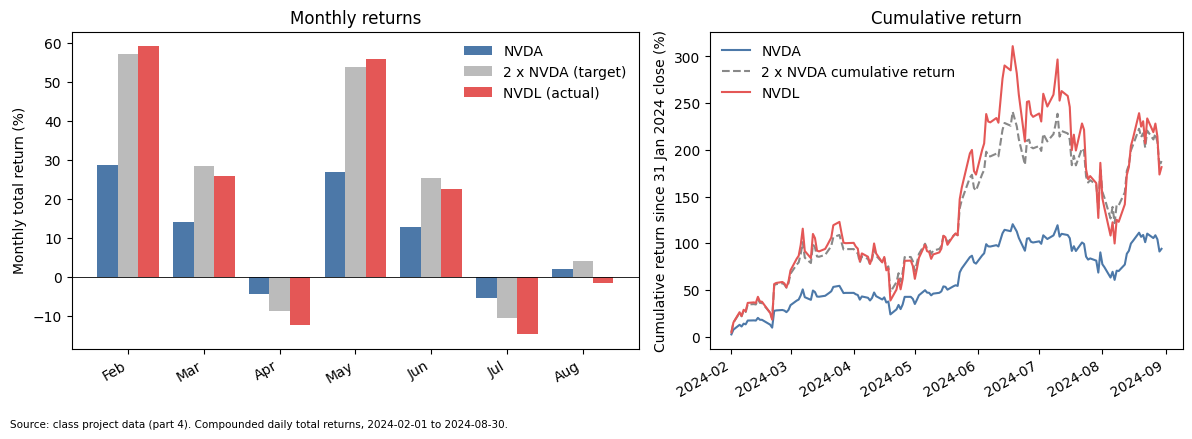

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})

m = tbl.iloc[:-1]
x = np.arange(len(m)); w = 0.27
ax[0].bar(x - w, m["NVDA"] * 100, w, label="NVDA", color="#4C78A8")
ax[0].bar(x, m["2 x NVDA"] * 100, w, label="2 x NVDA (target)", color="#BBBBBB")
ax[0].bar(x + w, m["NVDL"] * 100, w, label="NVDL (actual)", color="#E45756")
ax[0].axhline(0, color="k", lw=0.6)
ax[0].set_xticks(x); ax[0].set_xticklabels([s[:3] for s in m.index])
ax[0].set_ylabel("Monthly total return (%)"); ax[0].set_title("Monthly returns"); ax[0].legend(frameon=False)

cum = growth.cumprod() - 1
ax[1].plot(cum.index, cum["NVDA"] * 100, label="NVDA", color="#4C78A8")
ax[1].plot(cum.index, 2 * cum["NVDA"] * 100, label="2 x NVDA cumulative return", color="#888", ls="--")
ax[1].plot(cum.index, cum["NVDL"] * 100, label="NVDL", color="#E45756")
ax[1].set_ylabel("Cumulative return since 31 Jan 2024 close (%)"); ax[1].set_title("Cumulative return")
ax[1].legend(frameon=False); fig.autofmt_xdate()

fig.text(0.01, -0.03, "Source: class project data (part 4). Compounded daily total returns, 2024-02-01 to 2024-08-30.", fontsize=7.5)
plt.tight_layout(); fig.savefig(FIG / "4D_period_returns.png", bbox_inches="tight"); plt.show()